# Finite Relational Clock Model v7: Exact Finite Assignment Optimization

## Goal

For a fixed clock dimension \(N\), find the global minimum of the weighted energy-mismatch variance over every admissible ordered integer assignment and the continuous clock spacing. This strengthens v6's grid search: the integer assignments are exhaustively enumerated, and the best spacing for each assignment is calculated analytically.

**Scope:** global optimality is claimed only for the finite design problem defined here: a fixed finite target spectrum, fixed initial-state weights, a clock with \(N\) equally spaced levels, distinct ordered labels, and a freely chosen common energy offset. This does not establish a universal optimum for all clock models or prove that time is fundamentally circular.

We use \(\hbar=1\). Sort the distinct target energies as \(E_0<\cdots<E_{d-1}\), with normalized weights \(p_j=|c_j|^2\). An admissible assignment is
\[
0=q_0<q_1<\cdots<q_{d-1}<N.
\]
The approximate spectrum is \(\widetilde E_j=a+\Delta q_j\), where the common offset \(a\) does not affect pure-state fidelity. The objective is
\[
V(q,\Delta)=\operatorname{Var}_p(E-\Delta q).
\]


## 1. Analytic solution for a fixed integer assignment

Write weighted means as \(\bar E=\sum_jp_jE_j\) and \(\bar q=\sum_jp_jq_j\), and define weighted variances and covariance:
\[
V_E=\sum_jp_j(E_j-\bar E)^2,\quad
V_q=\sum_jp_j(q_j-\bar q)^2,
\]
\[
C_{Eq}=\sum_jp_j(E_j-\bar E)(q_j-\bar q).
\]
Expanding the objective gives
\[
V(q,\Delta)=V_E-2\Delta C_{Eq}+\Delta^2V_q.
\]
For a nonconstant assignment, \(V_q>0\), so the unique unconstrained minimizer is
\[
\boxed{\Delta_*(q)=\frac{C_{Eq}}{V_q}}.
\]
When this is positive, it is also the minimizer over \(\Delta>0\), and the minimized objective is
\[
\boxed{V_*(q)=V_E-\frac{C_{Eq}^2}{V_q}.}
\]
The target energies and labels are both strictly increasing, and all weights are positive in this example, so their weighted covariance is positive. We still check that condition in code rather than assume it silently.


## 2. Test spectrum and exact fixed-assignment solver

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=8, suppress=True)
E = np.array([0.0, 0.73, 1.41, 2.26])
c = np.array([1.0, 1.0j, 0.7, 0.4*np.exp(0.6j)], dtype=complex)
p = np.abs(c)**2
p = p / p.sum()
assert np.all(np.diff(E) > 0)
assert np.all(p > 0) and np.isclose(p.sum(), 1.0)

def weighted_stats(x, y=None, weights=p):
    x = np.asarray(x, dtype=float)
    w = np.asarray(weights, dtype=float); w = w / w.sum()
    mx = float(np.sum(w*x))
    vx = float(np.sum(w*(x-mx)**2))
    if y is None:
        return mx, vx
    y = np.asarray(y, dtype=float)
    my = float(np.sum(w*y))
    vy = float(np.sum(w*(y-my)**2))
    cov = float(np.sum(w*(x-mx)*(y-my)))
    return mx, vx, my, vy, cov

def solve_spacing_for_labels(E, q, weights=p):
    _, var_E, _, var_q, cov = weighted_stats(E, q, weights)
    if var_q <= 0:
        raise ValueError('Integer labels must not all be equal.')
    delta = cov / var_q
    if delta <= 0:
        return {'valid': False, 'delta': delta, 'variance': np.nan, 'covariance': cov}
    variance = max(0.0, var_E - cov**2 / var_q)
    # Fit common offset a to center residuals; this does not affect fidelity.
    offset = float(np.sum((weights/weights.sum()) * (E - delta*np.asarray(q))))
    E_approx = offset + delta*np.asarray(q)
    return {'valid': True, 'delta': float(delta), 'variance': float(variance),
            'covariance': cov, 'offset': offset, 'E_approx': E_approx}

print('Target energies:', E)
print('Weights:', p)


Target energies: [0.   0.73 1.41 2.26]
Weights: [0.37735849 0.37735849 0.18490566 0.06037736]


## 3. Exhaustive enumeration for a fixed clock dimension

In [2]:
def exhaustive_optimize(N, E=E, weights=p):
    d = len(E)
    if N < d:
        raise ValueError('Clock dimension must be at least the number of distinct system levels.')
    records = []
    # q_0 is anchored to zero; all remaining strictly increasing labels are enumerated.
    for tail in itertools.combinations(range(1, N), d-1):
        q = np.array((0,) + tail, dtype=int)
        sol = solve_spacing_for_labels(E, q, weights)
        if sol['valid']:
            records.append({'N': N, 'q': tuple(int(x) for x in q), **sol})
    if not records:
        raise RuntimeError('No valid assignments found.')
    frame = pd.DataFrame(records).sort_values(['variance','delta']).reset_index(drop=True)
    return frame

N_values = [4, 5, 6, 8, 12, 16, 24, 32, 48, 64]
results = []
all_searches = {}
for N in N_values:
    frame = exhaustive_optimize(N)
    all_searches[N] = frame
    best = frame.iloc[0]
    results.append({'N': N, 'assignments_checked': len(frame), 'q_star': best['q'],
                    'delta_star': best['delta'], 'variance_star': best['variance'],
                    'covariance': best['covariance']})
summary = pd.DataFrame(results)
display(summary)


,N,assignments_checked,q_star,delta_star,variance_star,covariance
0,4,1,"(0, 1, 2, 3)",0.728557,0.000731,0.581850
1,5,4,"(0, 1, 2, 3)",0.728557,0.000731,0.581850
2,6,10,"(0, 1, 2, 3)",0.728557,0.000731,0.581850
3,8,35,"(0, 2, 4, 6)",0.364279,0.000731,1.163700
4,12,165,"(0, 3, 6, 10)",0.230320,0.000534,1.841390
5,16,455,"(0, 4, 8, 13)",0.175146,0.000221,2.423240
6,24,1771,"(0, 6, 12, 19)",0.118348,0.000137,3.586939
7,32,4495,"(0, 10, 19, 31)",0.073482,0.000064,5.777996
8,48,16215,"(0, 13, 25, 40)",0.056441,0.000004,7.523546
9,64,39711,"(0, 13, 25, 40)",0.056441,0.000004,7.523546


## 4. Why this is a global optimum for the defined finite problem

For each fixed integer assignment \(q\), the objective is a convex quadratic in \(\Delta\), and the code evaluates its analytic minimizer. The loop enumerates every strictly increasing assignment \(0=q_0<q_1<\cdots<q_{d-1}<N\). Therefore, taking the smallest minimized variance across this finite list gives a global minimum for this specific finite design problem, subject to the stated assumptions.

This proof does **not** cover nonuniform clock spectra, different objective functions, constraints on the offset, finite-time fidelity optimization directly, or arbitrary physical clock models.


## 5. Evaluate fidelity and the analytic bound

,N,delta_star,variance_star,bound_at_T,sampled_min_fidelity,sampled_mean_fidelity
0,4,0.728557,0.000731,0.835466,0.853098,0.948751
1,5,0.728557,0.000731,0.835466,0.853098,0.948751
2,6,0.728557,0.000731,0.835466,0.853098,0.948751
3,8,0.364279,0.000731,0.835466,0.853098,0.948751
4,12,0.230320,0.000534,0.879901,0.887147,0.961428
5,16,0.175146,0.000221,0.950277,0.951241,0.983617
6,24,0.118348,0.000137,0.969253,0.969602,0.989820
7,32,0.073482,0.000064,0.985709,0.985817,0.995257
8,48,0.056441,0.000004,0.999174,0.999175,0.999725
9,64,0.056441,0.000004,0.999174,0.999175,0.999725


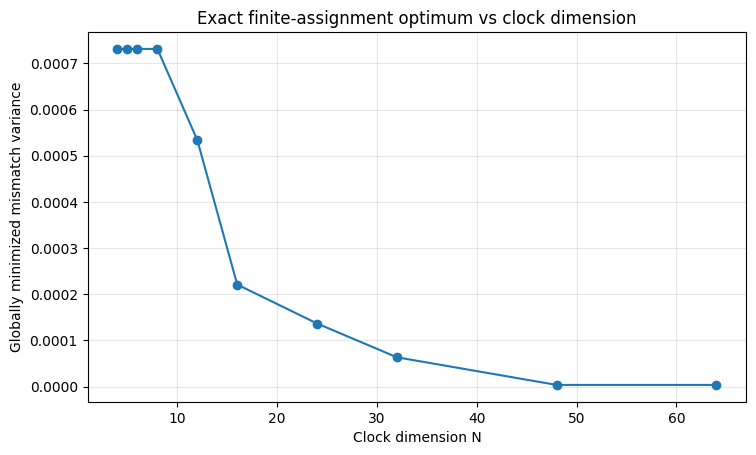

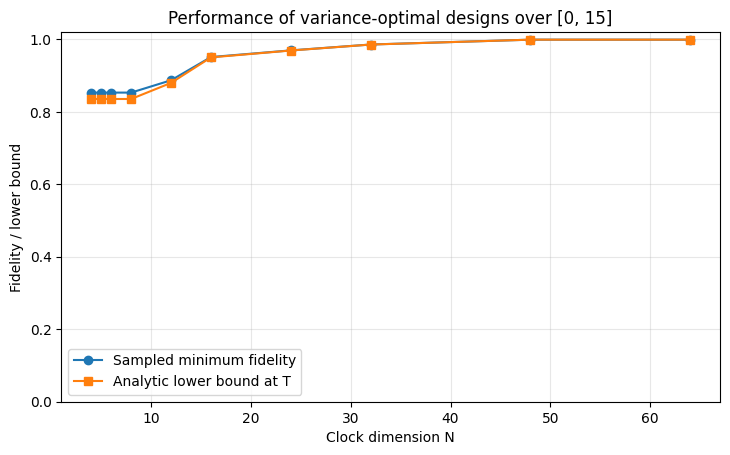

In [3]:
def fidelity(t, E_target, E_approx, weights=p):
    w = np.asarray(weights, dtype=float); w = w / w.sum()
    return float(abs(np.sum(w*np.exp(-1j*(np.asarray(E_target)-np.asarray(E_approx))*t)))**2)

def lower_bound(t, variance):
    return max(0.0, 1.0 - float(t)**2*float(variance))

T = 15.0
times = np.linspace(0, T, 4001)
fid_rows = []
for N in N_values:
    best = all_searches[N].iloc[0]
    E_approx = np.asarray(best['E_approx'])
    fs = np.array([fidelity(t, E, E_approx) for t in times])
    fid_rows.append({'N': N, 'delta_star': best['delta'], 'variance_star': best['variance'],
                     'bound_at_T': lower_bound(T, best['variance']),
                     'sampled_min_fidelity': float(fs.min()),
                     'sampled_mean_fidelity': float(fs.mean())})
fidelity_summary = pd.DataFrame(fid_rows)
display(fidelity_summary)

plt.figure(figsize=(8.5, 4.8))
plt.plot(fidelity_summary['N'], fidelity_summary['variance_star'], marker='o')
plt.xlabel('Clock dimension N')
plt.ylabel('Globally minimized mismatch variance')
plt.title('Exact finite-assignment optimum vs clock dimension')
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(8.5, 4.8))
plt.plot(fidelity_summary['N'], fidelity_summary['sampled_min_fidelity'], marker='o', label='Sampled minimum fidelity')
plt.plot(fidelity_summary['N'], fidelity_summary['bound_at_T'], marker='s', label='Analytic lower bound at T')
plt.xlabel('Clock dimension N')
plt.ylabel('Fidelity / lower bound')
plt.ylim(0, 1.02)
plt.title(f'Performance of variance-optimal designs over [0, {T:g}]')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## 6. Inspect the optimal assignment

Clock dimension N = 32
Globally optimal labels q* = [ 0 10 19 31]
Optimal spacing Δ* = 0.07348197068543122
Fitted common offset a = -0.00034242586242103773
Target energies = [0.   0.73 1.41 2.26]
Approximate energies = [-0.00034243  0.73447728  1.39581502  2.27759867]
Mismatch variance = 6.351400603155088e-05
Assignments exhaustively checked = 4495


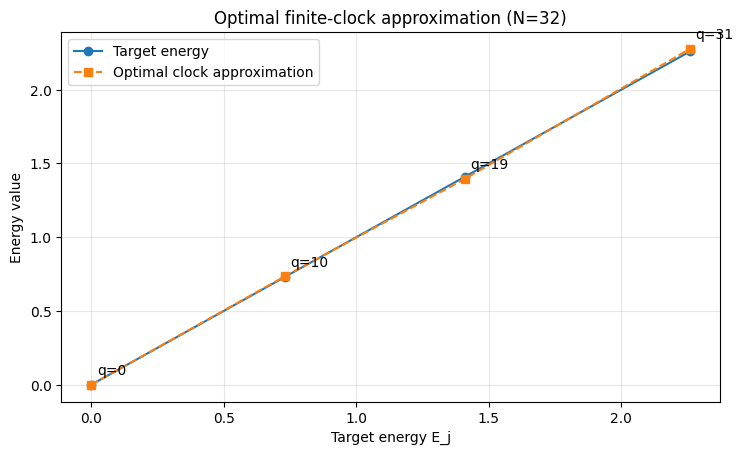

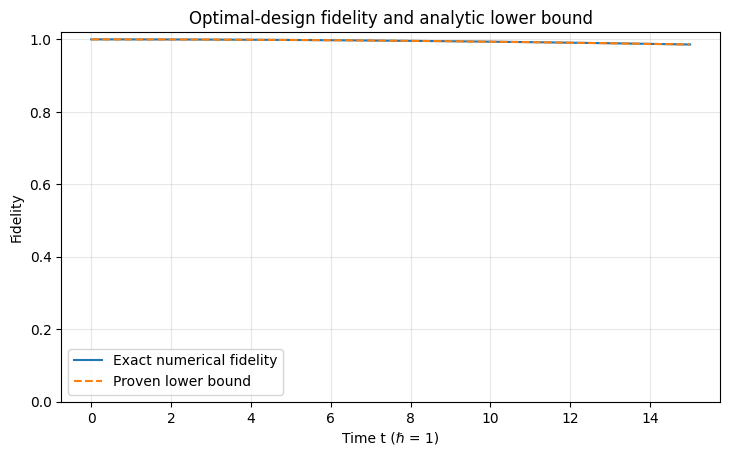

In [4]:
N_inspect = 32
best = all_searches[N_inspect].iloc[0]
q_star = np.array(best['q'], dtype=int)
Ea_star = np.asarray(best['E_approx'], dtype=float)
print('Clock dimension N =', N_inspect)
print('Globally optimal labels q* =', q_star)
print('Optimal spacing Δ* =', best['delta'])
print('Fitted common offset a =', best['offset'])
print('Target energies =', E)
print('Approximate energies =', Ea_star)
print('Mismatch variance =', best['variance'])
print('Assignments exhaustively checked =', len(all_searches[N_inspect]))

plt.figure(figsize=(8.5, 4.8))
plt.plot(E, E, 'o-', label='Target energy')
plt.plot(E, Ea_star, 's--', label='Optimal clock approximation')
for j in range(len(E)):
    plt.annotate(f'q={q_star[j]}', (E[j], Ea_star[j]), xytext=(4, 7), textcoords='offset points')
plt.xlabel('Target energy E_j')
plt.ylabel('Energy value')
plt.title(f'Optimal finite-clock approximation (N={N_inspect})')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

fs = np.array([fidelity(t, E, Ea_star) for t in times])
bs = np.array([lower_bound(t, best['variance']) for t in times])
plt.figure(figsize=(8.5, 4.8))
plt.plot(times, fs, label='Exact numerical fidelity')
plt.plot(times, bs, '--', label='Proven lower bound')
plt.xlabel('Time t (ℏ = 1)')
plt.ylabel('Fidelity')
plt.ylim(0, 1.02)
plt.title('Optimal-design fidelity and analytic lower bound')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## 7. Validation and proof checks

In [5]:
# Every admissible assignment count is binomial(N-1, d-1).
import math
for N in N_values:
    assert len(all_searches[N]) == math.comb(N-1, len(E)-1)

# For each stored optimum, labels are strictly increasing and in range.
for N in N_values:
    row = all_searches[N].iloc[0]
    q = np.asarray(row['q'])
    assert q[0] == 0 and np.all(np.diff(q) > 0) and q[-1] < N
    assert row['delta'] > 0
    # Recompute objective directly from fitted approximate spectrum.
    direct_var = weighted_stats(E - np.asarray(row['E_approx']))[1]
    assert np.isclose(direct_var, row['variance'], atol=1e-10)

# The analytic lower bound lies below the exact fidelity on a dense grid.
for N in [4, 8, 16, 32, 64]:
    row = all_searches[N].iloc[0]
    Ea = np.asarray(row['E_approx'])
    for t in np.linspace(0, T, 1001):
        assert fidelity(t, E, Ea) + 1e-10 >= lower_bound(t, row['variance'])

# A common offset changes neither fidelity nor variance.
shift = 2.71828
row = all_searches[32].iloc[0]
Ea = np.asarray(row['E_approx'])
assert np.isclose(weighted_stats(E-Ea)[1], weighted_stats((E+shift)-(Ea+shift))[1])
assert np.isclose(fidelity(3.7, E, Ea), fidelity(3.7, E+shift, Ea+shift))

print('PASS: exhaustive assignment count matches binomial formula')
print('PASS: all labels ordered and inside clock range')
print('PASS: analytic spacing/objective recomputation')
print('PASS: fidelity lower bound over dense time grids')
print('PASS: common-offset invariance')


PASS: exhaustive assignment count matches binomial formula
PASS: all labels ordered and inside clock range
PASS: analytic spacing/objective recomputation
PASS: fidelity lower bound over dense time grids
PASS: common-offset invariance


## 8. Conclusions and limits

### Established for this finite design problem

- For each fixed integer assignment, the weighted least-squares-optimal spacing is obtained analytically.
- All admissible ordered integer assignments are enumerated for each tested \(N\).
- The smallest minimized mismatch variance is therefore the global optimum for the stated finite assignment problem, up to ordinary floating-point arithmetic.
- The v5 fidelity bound gives a uniform sufficient condition over a chosen time horizon.

### Not established

- This is not a global optimum over nonuniform clock spectra or arbitrary clock/system interactions.
- Minimizing mismatch variance optimizes the stated sufficient lower bound, not necessarily the exact minimum fidelity over a finite interval.
- The time-domain fidelity minimum is sampled numerically, not proven continuously.
- The toy model does not prove that time is fundamentally circular, derive intrinsic decoherence, or prove the manuscript's winding/periodization theorem.

### Next research step

A natural next step is to derive a bound on the best achievable mismatch variance as a function of \(N\), the target spectrum, and the weights, and then determine whether the observed scaling can be proved for a class of spectra. A separate optimization could directly target minimum fidelity on a specified interval, but its oscillatory objective is more difficult than the quadratic variance objective.
